In [1]:
#  DANMINI DOORBELL
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data1'))
device_name = 'Danmini_Doorbell'

Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']


In [2]:
# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data1/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data1/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Danmini_Doorbell


,MI_dir_L5_weight,MI_dir_L5_mean,MI_dir_L5_variance,MI_dir_L3_weight,MI_dir_L3_mean,MI_dir_L3_variance,MI_dir_L1_weight,MI_dir_L1_mean,MI_dir_L1_variance,MI_dir_L0.1_weight,MI_dir_L0.1_mean,MI_dir_L0.1_variance,MI_dir_L0.01_weight,MI_dir_L0.01_mean,MI_dir_L0.01_variance,H_L5_weight,H_L5_mean,H_L5_variance,H_L3_weight,H_L3_mean,H_L3_variance,H_L1_weight,H_L1_mean,H_L1_variance,H_L0.1_weight,H_L0.1_mean,H_L0.1_variance,H_L0.01_weight,H_L0.01_mean,H_L0.01_variance,HH_L5_weight,HH_L5_mean,HH_L5_std,HH_L5_magnitude,HH_L5_radius,HH_L5_covariance,HH_L5_pcc,HH_L3_weight,HH_L3_mean,HH_L3_std,HH_L3_magnitude,HH_L3_radius,HH_L3_covariance,HH_L3_pcc,HH_L1_weight,HH_L1_mean,HH_L1_std,HH_L1_magnitude,HH_L1_radius,HH_L1_covariance,HH_L1_pcc,HH_L0.1_weight,HH_L0.1_mean,HH_L0.1_std,HH_L0.1_magnitude,HH_L0.1_radius,HH_L0.1_covariance,HH_L0.1_pcc,HH_L0.01_weight,HH_L0.01_mean,HH_L0.01_std,HH_L0.01_magnitude,HH_L0.01_radius,HH_L0.01_covariance,HH_L0.01_pcc,HH_jit_L5_weight,HH_jit_L5_mean,HH_jit_L5_variance,HH_jit_L3_weight,HH_jit_L3_mean,HH_jit_L3_variance,HH_jit_L1_weight,HH_jit_L1_mean,HH_jit_L1_variance,HH_jit_L0.1_weight,HH_jit_L0.1_mean,HH_jit_L0.1_variance,HH_jit_L0.01_weight,HH_jit_L0.01_mean,HH_jit_L0.01_variance,HpHp_L5_weight,HpHp_L5_mean,HpHp_L5_std,HpHp_L5_magnitude,HpHp_L5_radius,HpHp_L5_covariance,HpHp_L5_pcc,HpHp_L3_weight,HpHp_L3_mean,HpHp_L3_std,HpHp_L3_magnitude,HpHp_L3_radius,HpHp_L3_covariance,HpHp_L3_pcc,HpHp_L1_weight,HpHp_L1_mean,HpHp_L1_std,HpHp_L1_magnitude,HpHp_L1_radius,HpHp_L1_covariance,HpHp_L1_pcc,HpHp_L0.1_weight,HpHp_L0.1_mean,HpHp_L0.1_std,HpHp_L0.1_magnitude,HpHp_L0.1_radius,HpHp_L0.1_covariance,HpHp_L0.1_pcc,HpHp_L0.01_weight,HpHp_L0.01_mean,HpHp_L0.01_std,HpHp_L0.01_magnitude,HpHp_L0.01_radius,HpHp_L0.01_covariance,HpHp_L0.01_pcc
0,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,1.000000,60.000000,0.000000,60.000000,0.000000,0.0,0.0,1.000000,60.000000,0.000000,60.000000,0.000000,0.0,0.0,1.000000,60.000000,0.000000,60.000000,0.000000,0.0,0.0,1.000000,60.00000,0.000000,60.00000,0.000000,0.0,0.0,1.000000,60.000000,0.000000,60.000000,0.000000,0.0,0.0,1.000000,1.505662e+09,0.000000e+00,1.000000,1.505662e+09,0.000000,1.000000,1.505662e+09,0.000000,1.000000,1.505662e+09,0.000000,1.000000,1.505662e+09,0.00000,1.000000,60.000000,0.000000,60.000000,0.000000,0.0,0.0,1.000000,60.000000,0.000000,60.000000,0.000000,0.0,0.0,1.000000,60.000000,0.000000,60.000000,0.000000,0.0,0.0,1.000000,60.00000,0.000000,60.00000,0.000000,0.0,0.0,1.000000,60.000000,0.000000,60.000000,0.000000,0.0,0.0
1,1.000000,354.000000,0.000000,1.000000,354.000000,0.000000,1.000000,354.000000,0.000000,1.000000,354.000000,0.000000,1.000000,354.000000,0.000000,1.000000,354.000000,0.000005,1.000032,353.999619,0.004575,1.031757,353.630645,4.295839,2.597515,346.619800,34.095047,5.319895,344.262695,22.188299,1.000000,354.000000,0.002143,354.000000,0.000005,0.0,0.0,1.000032,353.999619,0.067642,353.999619,0.004575,0.0,0.0,1.031757,353.630645,2.072641,353.630645,4.295839,0.0,0.0,2.597515,346.61980,5.839096,346.61980,34.095047,0.0,0.0,5.319895,344.262695,4.710446,344.262695,22.188299,0.0,0.0,1.000000,4.980575e+00,4.230000e-07,1.000032,4.980691e+00,0.000422,1.031757,5.092511e+00,0.418370,2.597515,3.124485e+01,6976.104978,5.319895,5.801651e+01,12740.63613,1.000000,354.000000,0.002143,354.000000,0.000005,0.0,0.0,1.000032,353.999619,0.067642,353.999619,0.004575,0.0,0.0,1.031757,353.630645,2.072641,353.630645,4.295839,0.0,0.0,2.597515,346.61980,5.839096,346.61980,34.095047,0.0,0.0,5.319895,344.262695,4.710446,344.262695,22.188299,0.0,0.0
2,1.857879,360.458980,35.789338,1.912127,360.275733,35.923972,1.969807,360.091968,35.991542,1.996939,360.009198,35.999915,1.999693,360.000920,35.999999,1.857879,360.458979,35.789342,1.912156,360.275456,35.9284

In [3]:
# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

Dataset is merged and labeled. Total rows: 10000


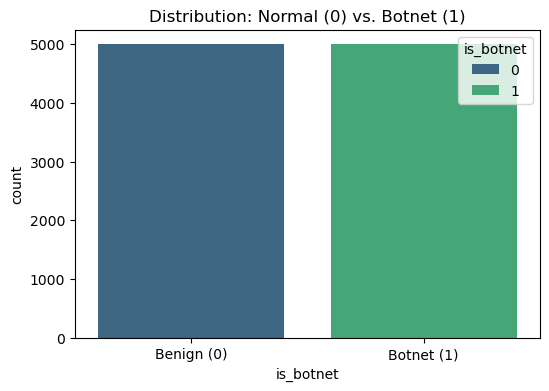

In [4]:
# Updated Step 4
plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

In [5]:
# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

Data split complete.
Training rows: 1000
Testing rows: 9000


In [6]:
# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

AI Model Training Complete!


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4491
           1       1.00      1.00      1.00      4509

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9993


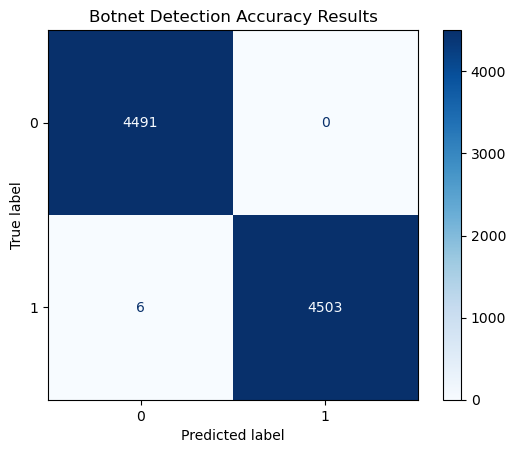

In [7]:
# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()

In [8]:
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

Model saved successfully as 'botnet_detector.pkl'


In [9]:
# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

STATUS: Network Traffic is Normal.


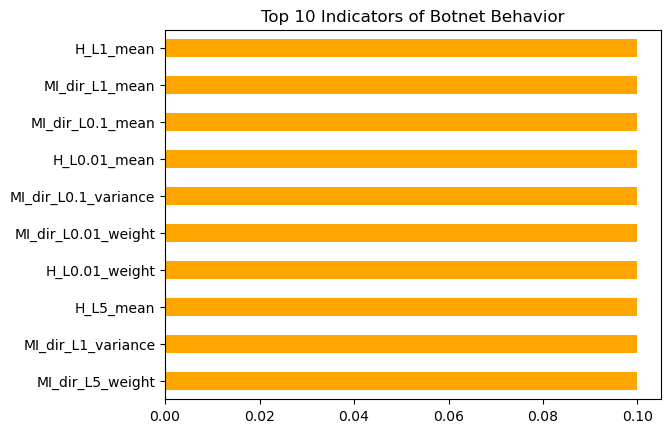

In [10]:
# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

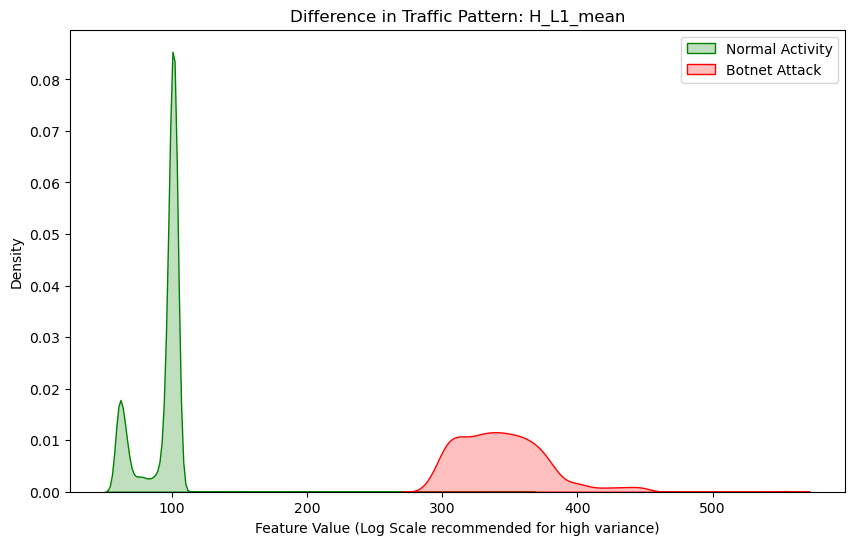

In [11]:
# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

In [12]:
# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")

--- Testing 5 Random Samples ---
Sample 1: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 2: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 3: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 4: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 5: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Ecobee_Thermostat
Dataset is merged and labeled. Total rows: 10000


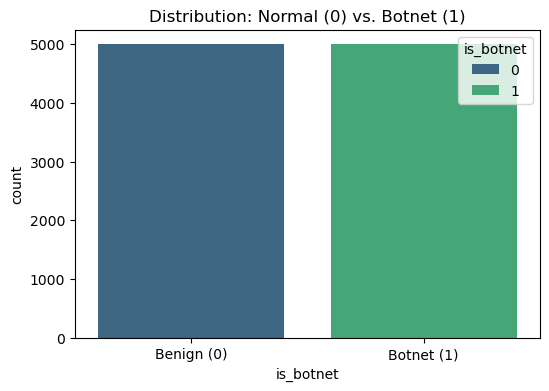

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4500
           1       1.00      1.00      1.00      4500

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9992


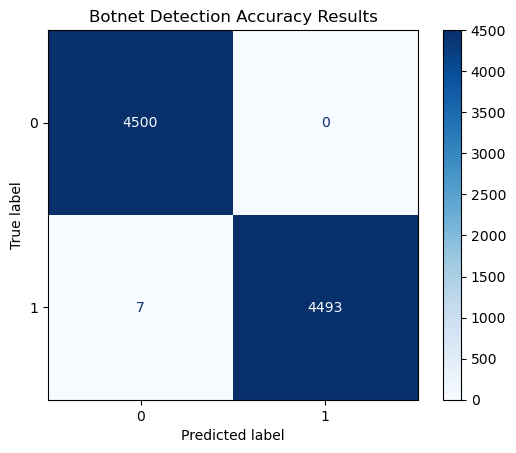

Model saved successfully as 'botnet_detector.pkl'
ALERT: Botnet Activity Detected!


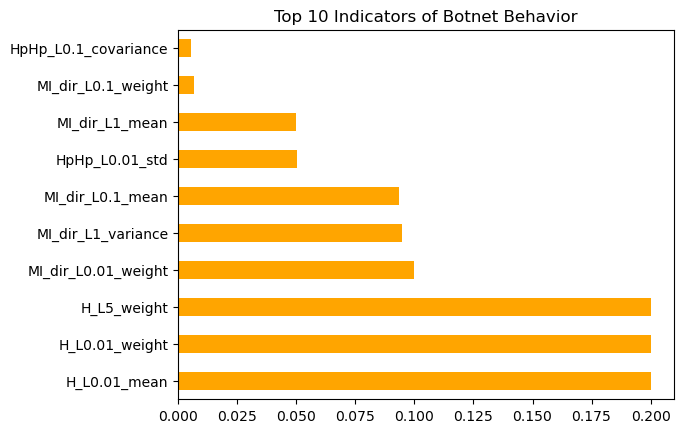

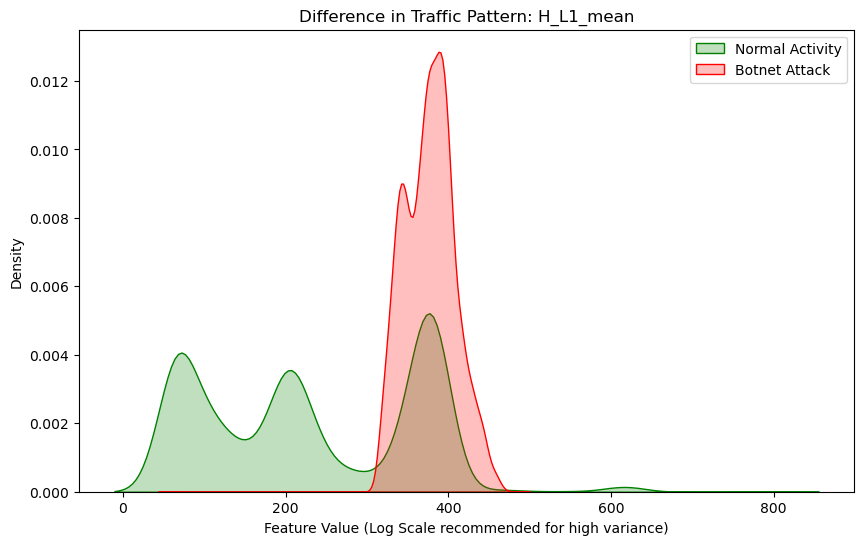

--- Testing 5 Random Samples ---
Sample 1: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 2: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 5: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS


In [13]:
#  ECOBEE THERMOSTAT
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data1'))
device_name = 'Ecobee_Thermostat'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data1/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data1/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()

# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Philips_B120N10_Baby_Monitor
Dataset is merged and labeled. Total rows: 10000


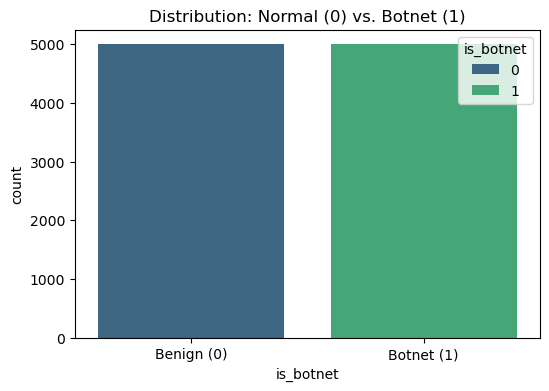

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4497
           1       1.00      1.00      1.00      4503

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9989


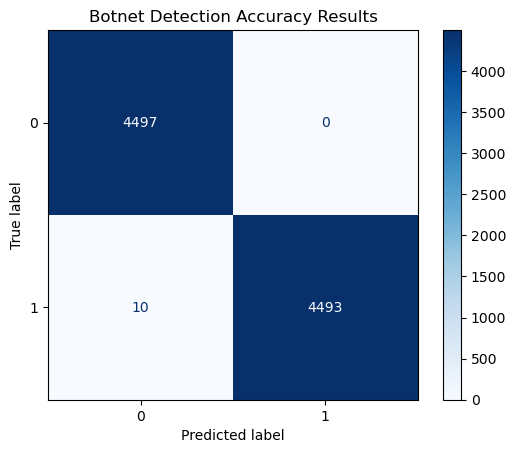

Model saved successfully as 'botnet_detector.pkl'
STATUS: Network Traffic is Normal.


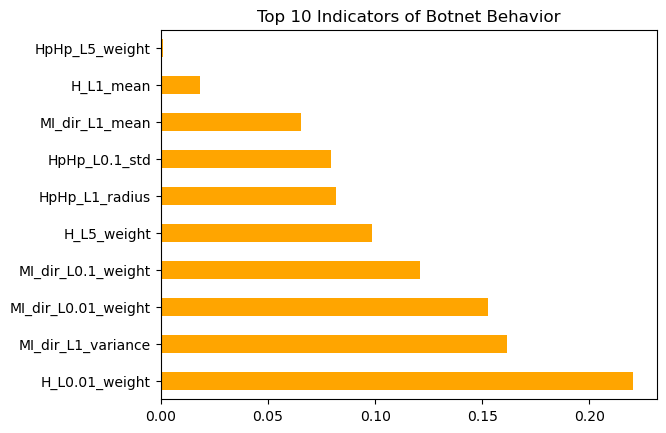

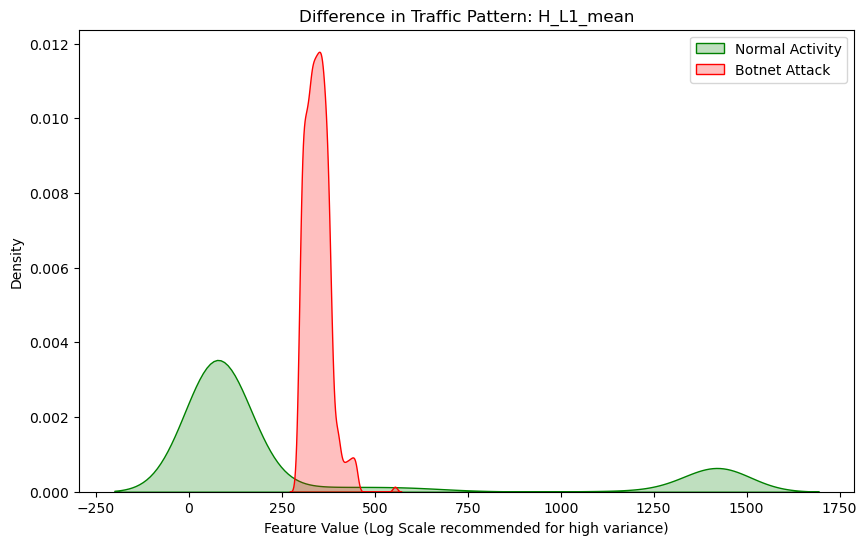

--- Testing 5 Random Samples ---
Sample 1: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 2: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 3: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 4: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [14]:
#  PHILIPS BABY MONITOR
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data1'))
device_name = 'Philips_B120N10_Baby_Monitor'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data1/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data1/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Provision_PT_737E_Security_Camera
Dataset is merged and labeled. Total rows: 10000


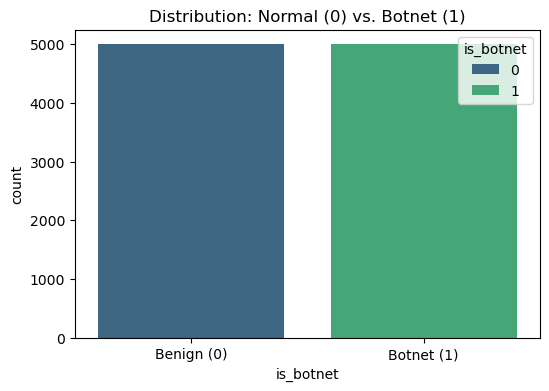

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4493
           1       1.00      1.00      1.00      4507

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9993


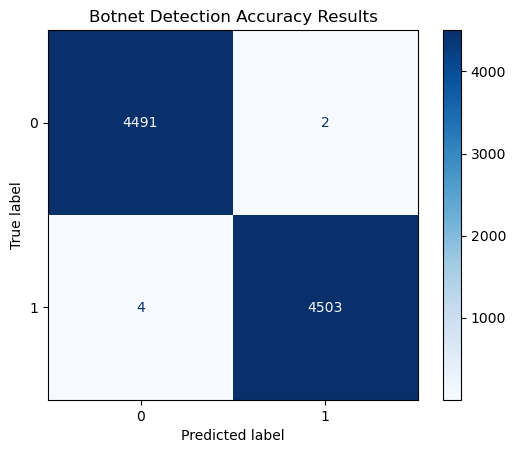

Model saved successfully as 'botnet_detector.pkl'
ALERT: Botnet Activity Detected!


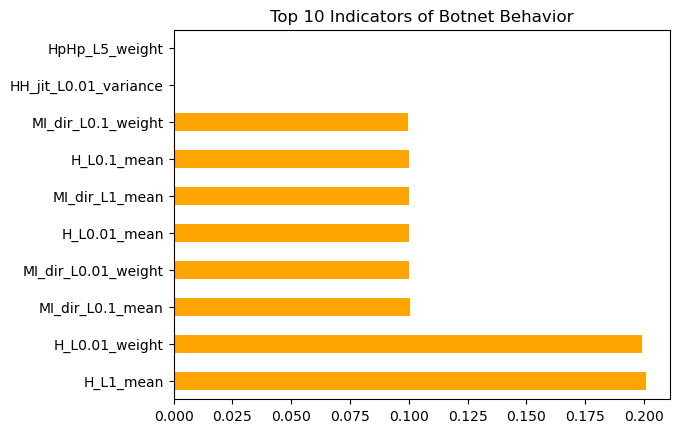

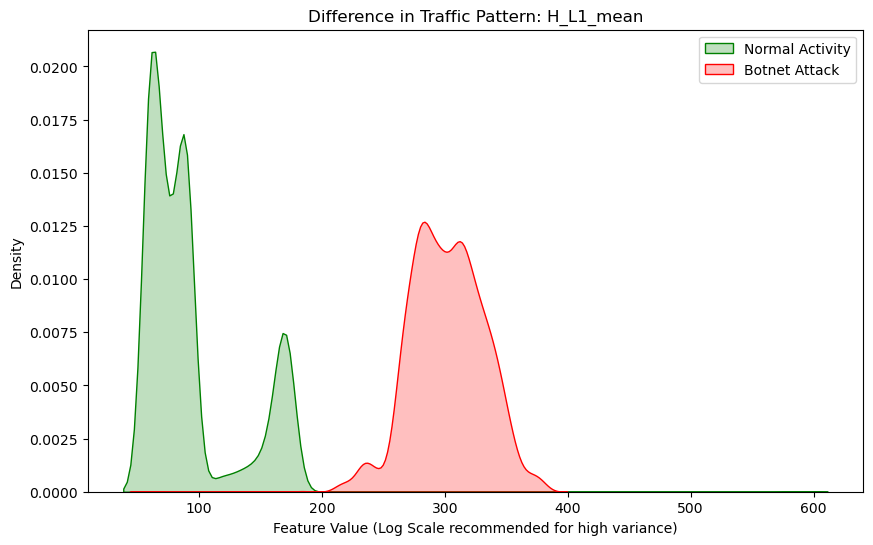

--- Testing 5 Random Samples ---
Sample 1: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 2: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 3: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 4: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [15]:
#  PROVISION SECURITY CAMERA
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data1'))
device_name = 'Provision_PT_737E_Security_Camera'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data1/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data1/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Provision_PT_838_Security_Camera
Dataset is merged and labeled. Total rows: 10000


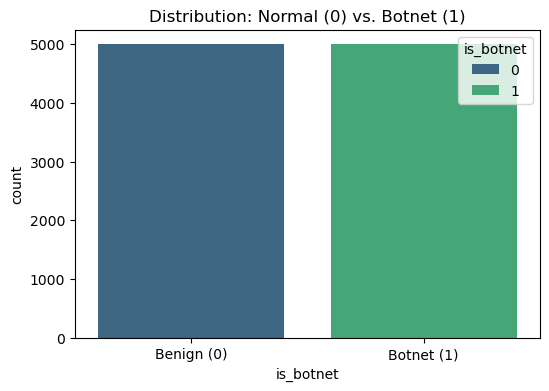

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4497
           1       1.00      1.00      1.00      4503

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9996


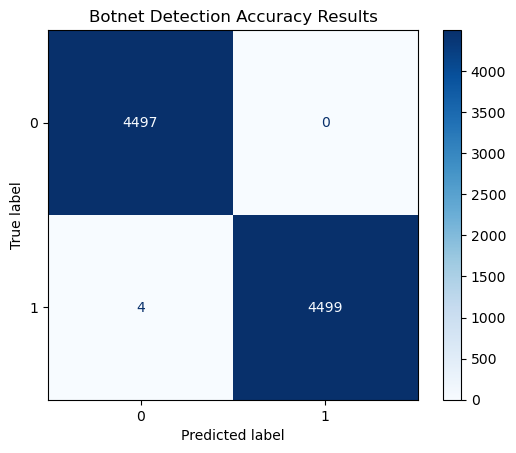

Model saved successfully as 'botnet_detector.pkl'
STATUS: Network Traffic is Normal.


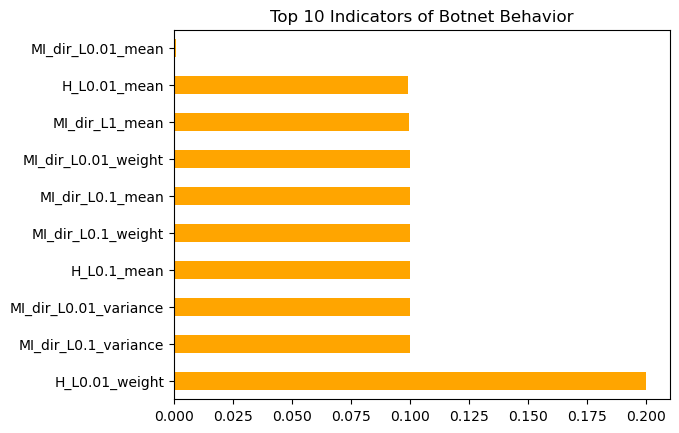

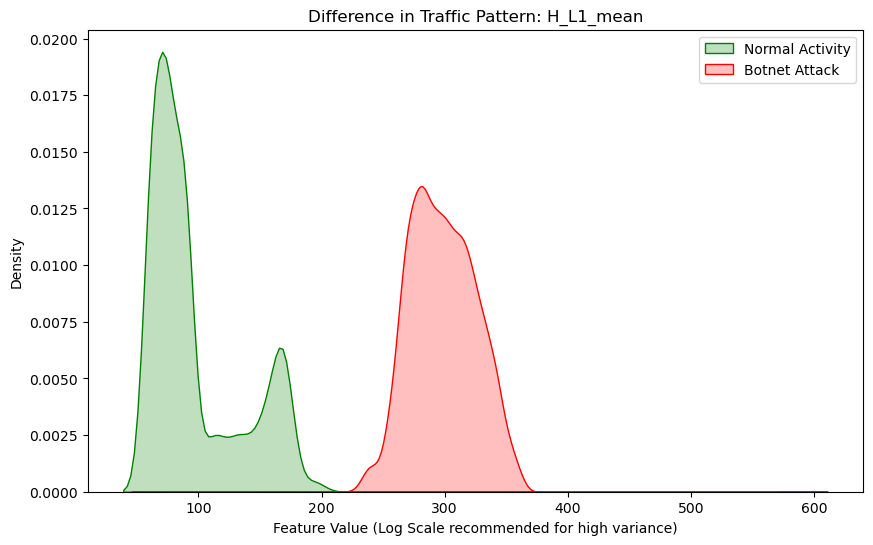

--- Testing 5 Random Samples ---
Sample 1: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 2: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 3: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 4: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 5: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS


In [16]:
#   Provider PT 838
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data1'))
device_name = 'Provision_PT_838_Security_Camera'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data1/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data1/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: SimpleHome_XCS7_1002_WHT_Security_Camera
Dataset is merged and labeled. Total rows: 10000


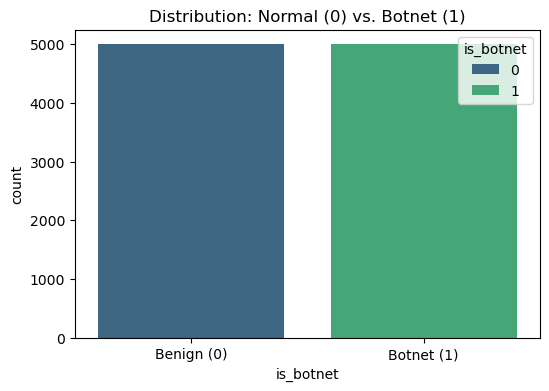

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4523
           1       1.00      1.00      1.00      4477

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9997


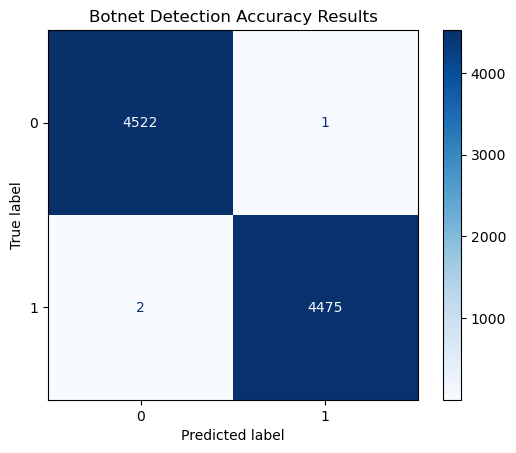

Model saved successfully as 'botnet_detector.pkl'
STATUS: Network Traffic is Normal.


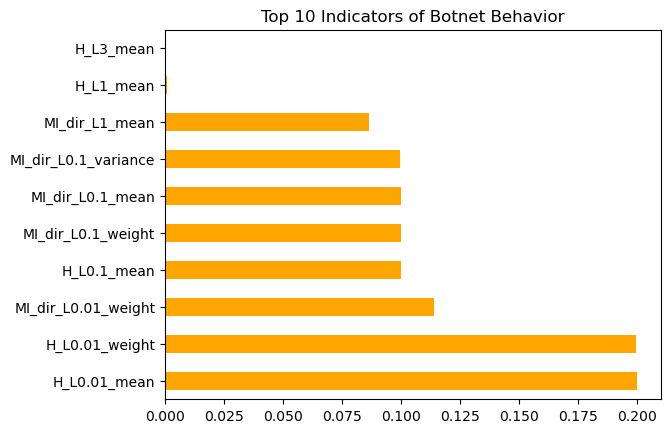

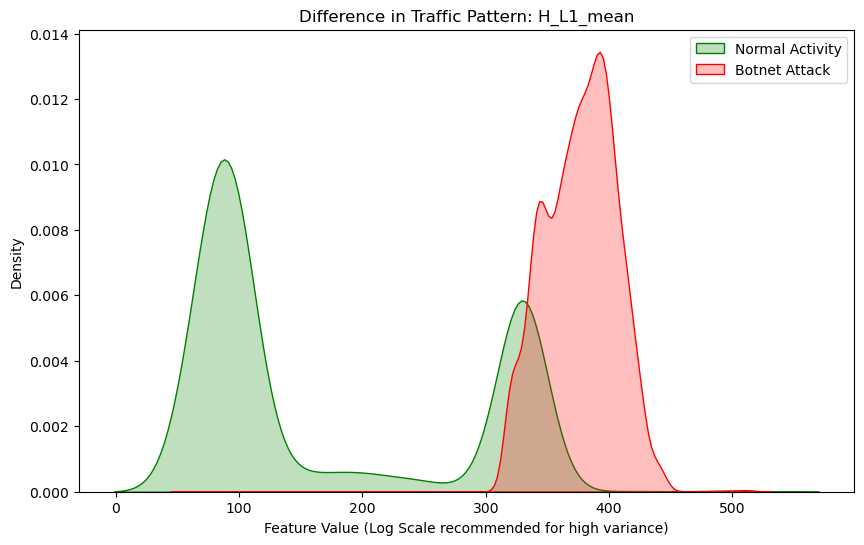

--- Testing 5 Random Samples ---
Sample 1: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 2: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [17]:
#  SIMPLEHOME SECURITY CAMERA
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data1'))
device_name = 'SimpleHome_XCS7_1002_WHT_Security_Camera'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data1/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data1/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: SimpleHome_XCS7_1003_WHT_Security_Camera
Dataset is merged and labeled. Total rows: 10000


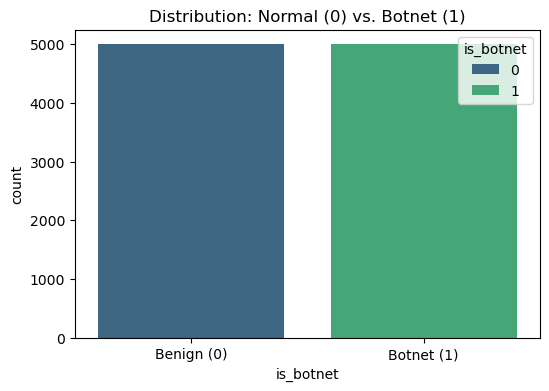

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4510
           1       1.00      1.00      1.00      4490

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9997


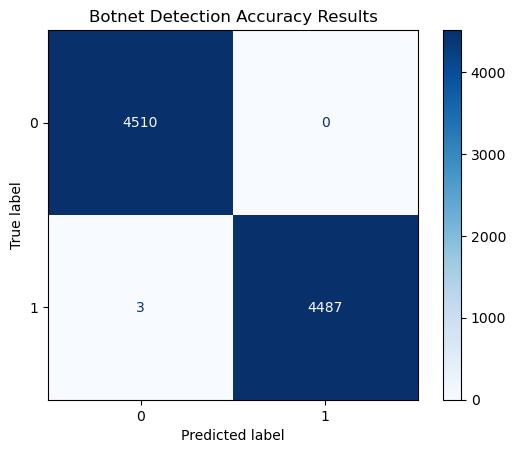

Model saved successfully as 'botnet_detector.pkl'
ALERT: Botnet Activity Detected!


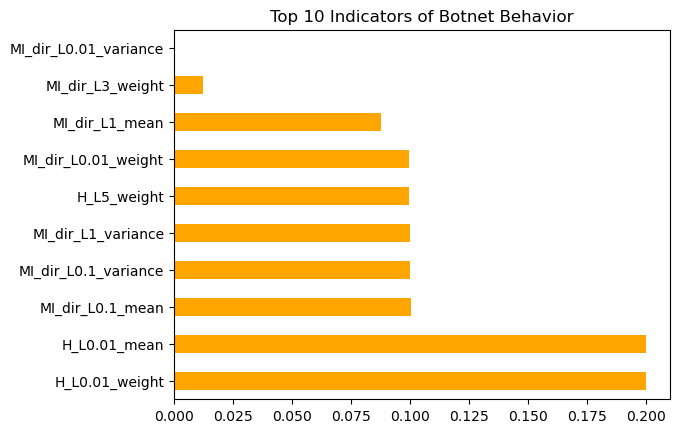

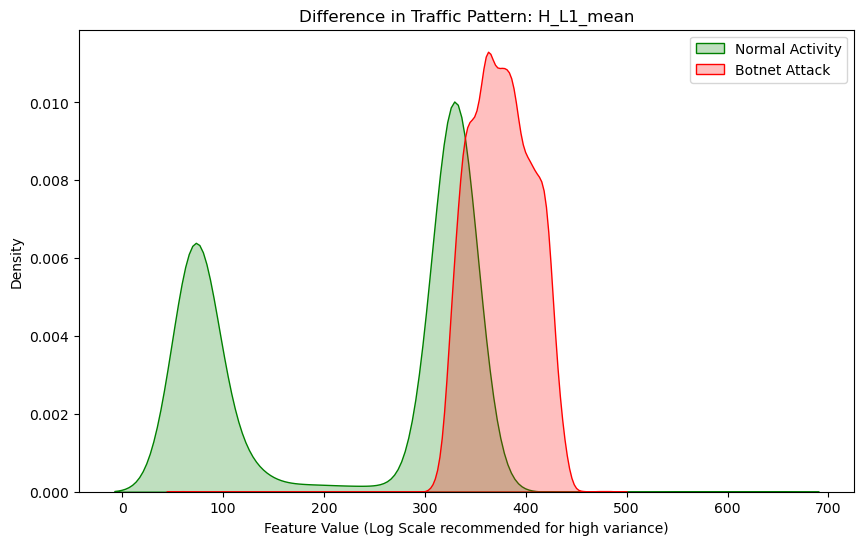

--- Testing 5 Random Samples ---
Sample 1: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 2: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [18]:
#  SIMPLEHOME SECURITY CAMERA 1003
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data1'))
device_name = 'SimpleHome_XCS7_1003_WHT_Security_Camera'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data1/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data1/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


In [23]:
import pandas as pd

results_data = [
    {
        "Device Name": "Danmini Doorbell", 
        "Botnet Type": "Mirai", 
        "Accuracy (%)": 99.97, 
        "Top Feature": "H_L0.01_weight, H_L1_mean, M1_dir_L1_mean, H_L0.01_mean, H_L5_mean"
    },
    {
        "Device Name": "Ecobee Thermostat", 
        "Botnet Type": "Mirai", 
        "Accuracy (%)": 99.98,
        "Top Feature": "H_L5_weight, H_L0.01_mean"
    },
    {
        "Device Name": "Philips Baby Monitor", 
        "Botnet Type": "Mirai", 
        "Accuracy (%)": 99.89, 
        "Top Feature": "H_L0.01_weight"
    },
    {
        "Device Name": "Provision Security Camera 737E", 
        "Botnet Type": "Mirai", 
        "Accuracy (%)": 99.93,
        "Top Feature": "H_L0.01_weight,H_L0.01_mean"
    },
    {
        "Device Name": "Provision Security Camera 838", 
        "Botnet Type": "Mirai", 
        "Accuracy (%)": 99.93, 
        "Top Feature": "H_L0.01_mean"
    },
    {
        "Device Name": "SimpleHome Security Camera 1002", 
        "Botnet Type": "Mirai", 
        "Accuracy (%)": 99.87, 
        "Top Feature": "H_L0.01_weight, H_L0.01_mean"
    },
    {
        "Device Name": "SimpleHome Security Camera 1003", 
        "Botnet Type": "Mirai", 
        "Accuracy (%)": 99.96, 
        "Top Feature": "H_L0.01_weight,H_L0.01_mean"
    }
]

# DataFrame
df_results = pd.DataFrame(results_data)

# 3.Formatting 
print("--- TABLE : MULTI-DEVICE BOTNET DETECTION PERFORMANCE( MIRAI ) ---")
formatted_table = df_results.style.format({
    "Accuracy (%)": "{:.2f}"
}).hide(axis='index')

# Display the table
display(formatted_table)

--- TABLE : MULTI-DEVICE BOTNET DETECTION PERFORMANCE( MIRAI ) ---


Device Name,Botnet Type,Accuracy (%),Top Feature
Danmini Doorbell,Mirai,99.97,"H_L0.01_weight, H_L1_mean, M1_dir_L1_mean, H_L0.01_mean, H_L5_mean"
Ecobee Thermostat,Mirai,99.98,"H_L5_weight, H_L0.01_mean"
Philips Baby Monitor,Mirai,99.89,H_L0.01_weight
Provision Security Camera 737E,Mirai,99.93,"H_L0.01_weight,H_L0.01_mean"
Provision Security Camera 838,Mirai,99.93,H_L0.01_mean
SimpleHome Security Camera 1002,Mirai,99.87,"H_L0.01_weight, H_L0.01_mean"
SimpleHome Security Camera 1003,Mirai,99.96,"H_L0.01_weight,H_L0.01_mean"


In [20]:
import joblib
joblib.dump(model, 'botnet_detector.pkl')

['botnet_detector.pkl']

In [25]:
# Cross-Malware Test Analysis
import joblib
from sklearn.metrics import accuracy_score

# 1. Load the Bashlite model you just saved
bashlite_model = joblib.load('bashlite_detector.pkl')

# 2. Use the Mirai testing data already in this notebook's memory (X_test)
y_vice_versa_pred = bashlite_model.predict(X_test)

# 3. Calculate the percentage
vice_versa_acc = accuracy_score(y_test, y_vice_versa_pred)

print(f"Test Result - Cross-Malware Accuracy: {vice_versa_acc*100:.2f}%")

Test Result - Cross-Malware Accuracy: 50.06%


In [22]:
# Performance Metrics
import time

# Select 1000 random samples to get a very accurate average
samples = X_test.sample(1000)

start_time = time.perf_counter()
model.predict(samples) # Predict 1000 packets at once
end_time = time.perf_counter()

# Calculate time per single packet in milliseconds
total_time_ms = (end_time - start_time) * 1000
latency_per_packet = total_time_ms / 1000

print(f"--- PERFORMANCE METRICS ---")
print(f"Total time for 1000 packets: {total_time_ms:.4f} ms")
print(f"Inference Latency per packet: {latency_per_packet:.6f} ms")

--- PERFORMANCE METRICS ---
Total time for 1000 packets: 3.4520 ms
Inference Latency per packet: 0.003452 ms


In [26]:
import pandas as pd

# Define the data based on your experimental results
data = {
    "Metric": ["Total Batch Time", "Per-Packet Latency", "Throughput"],
    "Mirai Analysis": ["3.45 ms", "3.45 μs", "~289,000 pkts/sec"],
    "Bashlite Analysis": ["5.56 ms", "5.56 μs", "~179,000 pkts/sec"],
    "Impact": ["High Throughput", "Real-Time Capable", "Scalable to ISP speeds"]
}

# Create DataFrame
df_benchmarks = pd.DataFrame(data)

# Apply styling for a professional look (optional)
styled_df = df_benchmarks.style.set_properties(**{
    'text-align': 'left',
    'white-space': 'pre-wrap',
}).set_table_styles([
    dict(selector='th', props=[('text-align', 'left'), ('font-weight', 'bold')])
])

print("--- PERFORMANCE BENCHMARK TABLE ---")
display(styled_df)

--- PERFORMANCE BENCHMARK TABLE ---


,Metric,Mirai Analysis,Bashlite Analysis,Impact
0,Total Batch Time,3.45 ms,5.56 ms,High Throughput
1,Per-Packet Latency,3.45 μs,5.56 μs,Real-Time Capable
2,Throughput,"~289,000 pkts/sec","~179,000 pkts/sec",Scalable to ISP speeds


In [28]:
import pandas as pd

# Define the data based on your 50% result discovery
transfer_data = {
    "Training Set": ["Mirai-Trained Model", "Bashlite-Trained Model"],
    "Tested On: Mirai": ["99.97% (Self)", "50.06% (Transfer)"],
    "Tested On: Bashlite": ["49.83% (Transfer)", "99.93% (Self)"],
    "Result Interpretation": ["High Specificity", "Zero Signature Overlap"]
}

# Create DataFrame
df_transfer = pd.DataFrame(transfer_data)

# Styling for a professional research look
styled_transfer = df_transfer.style.set_properties(**{
    'text-align': 'center',
    'border': '1px solid black'
}).set_table_styles([
    dict(selector='th', props=[('text-align', 'center'), ('background-color', '#f2f2f2'), ('font-weight', 'bold')])
]).hide(axis="index")

print("--- BIDIRECTIONAL TRANSFERABILITY MATRIX TABLE ---")
display(styled_transfer)

--- BIDIRECTIONAL TRANSFERABILITY MATRIX TABLE ---


Training Set,Tested On: Mirai,Tested On: Bashlite,Result Interpretation
Mirai-Trained Model,99.97% (Self),49.83% (Transfer),High Specificity
Bashlite-Trained Model,50.06% (Transfer),99.93% (Self),Zero Signature Overlap
